# 01a time of flight: what the success flag checks

Quantum Machines' `01a_time_of_flight` node plays a readout pulse, records the raw ADC trace, finds
where the pulse arrives, and adds that delay to the stored time of flight. This notebook runs QM's
analysis (through this repo's mirror of it) on traces where the right answer is known, to make
visible what its success flag checks: the ADC offsets, not the arrival edge. A trace with no pulse
in it therefore also reports success, which is useful to know when reading the node's output.

Sections 1 to 3 and the first half of 5 do not depend on this repo's simulator: they use synthetic
traces built in the notebook. Section 4 does depend on it, and says so.

All QM code quoted here is from qua-libs at commit
[`63f10b5`](https://github.com/qua-platform/qua-libs/tree/63f10b5f852af5898fac2d57706fdc79739d1617) [vendor], so the line links stay
valid if the files change.

In [1]:
import copy
import dataclasses
import logging
import sys
import time
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "calibration_utils").is_dir():
    ROOT = ROOT.parent  # run from notebooks/
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from scipy.signal import savgol_filter

from calibration_utils import style
from calibration_utils import time_of_flight as tof_analysis
from calibration_utils.common import INITIAL_STATE_PATH, QUBIT, NodeContext, load_node, load_state
from simulator.device import TRUE_DEVICE
from simulator.qpu import SimulatedQPU

%matplotlib inline
logging.disable(logging.INFO)  # the node logs one line per run
T_START = time.perf_counter()
THEME = "light"
P = style.palette(THEME)
MV = 1e3
node = load_node("01a_time_of_flight.py")

## 1. What 01a does, and two parameter facts

The node records the averaged ADC trace of both inputs over a window that opens at the stored time
of flight. Its analysis
([analysis.py](https://github.com/qua-platform/qua-libs/blob/63f10b5f852af5898fac2d57706fdc79739d1617/qualibration_graphs/superconducting/calibration_utils/time_of_flight/analysis.py) [vendor]) smooths |IQ| with a Savitzky-Golay filter (window 11, order 3),
sets a threshold, takes the first sample above the threshold as the delay, rounds it to the 4 ns
clock, and takes the mean of each input as its DC offset.

Two lines of the node's parameters
([parameters.py, lines 10 to 13](https://github.com/qua-platform/qua-libs/blob/63f10b5f852af5898fac2d57706fdc79739d1617/qualibration_graphs/superconducting/calibration_utils/time_of_flight/parameters.py#L10-L13) [vendor]) have docstrings that give other values than the code defaults:

```python
time_of_flight_in_ns: Optional[int] = None
"""Time of flight in nanoseconds. Default is 28 ns."""
readout_amplitude_in_v: Optional[float] = 0.03
"""Readout amplitude in volts. Default is 0.1 V."""
```

When the amplitude is not set, the node runs at 0.03 V; the docstring gives 0.1 V. `None` for the
time of flight means the node keeps the value already stored. This repo's node defaults to 0.1 V.

## 2. What the success flag checks

These are QM's threshold, delay and success lines
([analysis.py, lines 75 to 79](https://github.com/qua-platform/qua-libs/blob/63f10b5f852af5898fac2d57706fdc79739d1617/qualibration_graphs/superconducting/calibration_utils/time_of_flight/analysis.py#L75-L79) and
[lines 116 to 120](https://github.com/qua-platform/qua-libs/blob/63f10b5f852af5898fac2d57706fdc79739d1617/qualibration_graphs/superconducting/calibration_utils/time_of_flight/analysis.py#L116-L120) [vendor]):

```python
ds_fit["threshold"] = (
    ds_fit["filtered_adc"][:, 100:].mean("readout_time") + ds_fit["filtered_adc"][:, :-100].mean("readout_time")
) / 2
ds_fit["delay"] = (ds_fit["filtered_adc"] > ds_fit["threshold"]).where(True).idxmax("readout_time")
ds_fit["delay"] = np.round(ds_fit["delay"] / 4) * 4
...
nan_success = (
    np.isnan(ds_fit.delay.data) & np.isnan(ds_fit.offsets_I_mean.data) & np.isnan(ds_fit.offsets_Q_mean.data)
)
offset_success = (np.abs(ds_fit.offsets_I_mean) < 0.5) & (np.abs(ds_fit.offsets_Q_mean) < 0.5)
success_criteria = ~nan_success & offset_success.data
```

`idxmax` over a boolean array returns the first `True`, and the first coordinate if there is none,
so the delay is never NaN. Success then means "both offsets inside ±0.5 V". The flag does
not test whether an edge is present; the node's plot is where that shows.

The repo's mirror is `calibration_utils/time_of_flight.py` (`fit_raw_data`). The next cell
transcribes QM's lines above into a function and asserts that the mirror gives the same threshold,
delay, offsets and success on every trace this notebook uses. The transcription drops QM's
per-controller averaging of offsets over qubits, which is the identity for one qubit. One difference
is kept on purpose: when no sample is above the threshold the mirror returns NaN where QM returns the
first coordinate. That cannot happen for a non-constant trace, because the threshold sits near the
trace mean (section 3), so the assertion also checks that some sample is above it.

In [2]:
def _filter_adc_signal(data, window_length=11, polyorder=3):
    # QM analysis.py lines 143 to 147
    return savgol_filter(data, window_length, polyorder)


def qm_fit(ds: xr.Dataset) -> dict:
    """QM's analysis.py lines 73 to 79, 95 to 96 and 116 to 120, for one qubit on one controller."""
    ds_fit = ds.copy()
    ds_fit["filtered_adc"] = xr.apply_ufunc(_filter_adc_signal, ds_fit.IQ_abs)
    ds_fit["threshold"] = (
        ds_fit["filtered_adc"][:, 100:].mean("readout_time") + ds_fit["filtered_adc"][:, :-100].mean("readout_time")
    ) / 2
    ds_fit["delay"] = (ds_fit["filtered_adc"] > ds_fit["threshold"]).where(True).idxmax("readout_time")
    ds_fit["delay"] = np.round(ds_fit["delay"] / 4) * 4
    offsets_I_mean = ds_fit.adcI.mean(dim="readout_time")  # one qubit: the per-controller mean is itself
    offsets_Q_mean = ds_fit.adcQ.mean(dim="readout_time")
    nan_success = np.isnan(ds_fit.delay.data) & np.isnan(offsets_I_mean.data) & np.isnan(offsets_Q_mean.data)
    offset_success = (np.abs(offsets_I_mean) < 0.5) & (np.abs(offsets_Q_mean) < 0.5)
    success_criteria = ~nan_success & offset_success.data
    return {
        "threshold": float(ds_fit.threshold[0]),
        "delay": float(ds_fit.delay[0]),
        "offset_I_to_add": float(offsets_I_mean[0]),
        "offset_Q_to_add": float(offsets_Q_mean[0]),
        "success": bool(success_criteria[0]),
        "filtered": ds_fit.filtered_adc.values[0],
    }


def assert_mirror_matches_qm(ds: xr.Dataset) -> dict:
    mine, qm = tof_analysis.fit_raw_data(ds), qm_fit(ds)
    assert (qm["filtered"] > qm["threshold"]).any()
    np.testing.assert_allclose(mine["filtered"], qm["filtered"], rtol=0, atol=1e-15)
    for key in ("threshold", "offset_I_to_add", "offset_Q_to_add"):
        assert np.isclose(mine[key], qm[key], rtol=0, atol=1e-15), key
    assert mine["delay"] == qm["delay"] and mine["success"] == qm["success"]
    return mine


def dataset_from_volts(i_v: np.ndarray, q_v: np.ndarray) -> xr.Dataset:
    """An averaged ADC record in QM's raw units (volts = -raw / 2**12), run through the mirror's
    process_raw_dataset (QM's lines 46 to 52)."""
    raw = {"adcI": -np.asarray(i_v) * 2**12, "adcQ": -np.asarray(q_v) * 2**12}
    raw["adc_single_runI"], raw["adc_single_runQ"] = raw["adcI"], raw["adcQ"]
    ds = xr.Dataset(
        {k: (("qubit", "readout_time"), v[None, :]) for k, v in raw.items()},
        coords={"qubit": [QUBIT], "readout_time": np.arange(len(i_v))},
    )
    return tof_analysis.process_raw_dataset(ds)

Two synthetic averaged traces, 1000 samples (a 1 µs window at 1 ns per sample), with the
simulator's true DC offsets of +1.2 and -0.8 mV:

- **No pulse.** Offsets plus white noise of 3.8 mV per sample and input, which is 38 mV per shot
  averaged over 100 shots. Nothing arrives in the window.
- **Pulse with a transient.** A clean 20 mV pulse arriving at sample 213 with 1 mV noise, plus a
  5-sample, 40 mV transient at sample 80. A single shot cannot put this into a 100-shot average
  (the ADC clips at ±0.5 V, so one shot moves the average by at most 5 mV), so read it as pickup
  repeated on every shot, for example a trigger-synchronous spur. It stands in for anything that
  crosses the threshold before the real edge.

In [3]:
N = 1000
rng = np.random.default_rng(0)
off_i, off_q = TRUE_DEVICE.adc_offsets
sigma_avg = TRUE_DEVICE.adc_sample_noise / np.sqrt(100)  # 3.8 mV per sample after 100 averages

no_pulse = dataset_from_volts(off_i + rng.normal(0, sigma_avg, N), off_q + rng.normal(0, sigma_avg, N))

t = np.arange(N)
TRUE_EDGE = 213
envelope = 20e-3 * (t >= TRUE_EDGE)
phase = 2 * np.pi * 50e6 * t * 1e-9
transient = 40e-3 * ((t >= 80) & (t < 85))
i_pulse = off_i + envelope * np.cos(phase) + rng.normal(0, 1e-3, N)
q_pulse = off_q + envelope * np.sin(phase) + rng.normal(0, 1e-3, N)
clean_pulse = dataset_from_volts(i_pulse, q_pulse)
spiked_pulse = dataset_from_volts(i_pulse + transient, q_pulse)

STORED_TOF = 24  # state_initial.json, the window opens here
synthetic = {"no pulse": no_pulse, "clean pulse": clean_pulse, "pulse with transient": spiked_pulse}
synthetic_fits = {}
for name, ds in synthetic.items():
    fit = assert_mirror_matches_qm(ds)
    synthetic_fits[name] = fit
    print(
        f"{name:22s} success={fit['success']!s:5s}  delay={fit['delay']:4.0f} ns  "
        f"stored time of flight would be {STORED_TOF + fit['delay']:.0f} ns  "
        f"threshold={fit['threshold'] * MV:.2f} mV"
    )
print("mirror matches QM's transcribed formulas on all three traces")
NO_PULSE_SUCCESS = synthetic_fits["no pulse"]["success"]
NO_PULSE_DELAY = synthetic_fits["no pulse"]["delay"]

no pulse               success=True   delay=   8 ns  stored time of flight would be 32 ns  threshold=4.88 mV
clean pulse            success=True   delay= 216 ns  stored time of flight would be 240 ns  threshold=16.77 mV
pulse with transient   success=True   delay=  80 ns  stored time of flight would be 104 ns  threshold=16.88 mV
mirror matches QM's transcribed formulas on all three traces


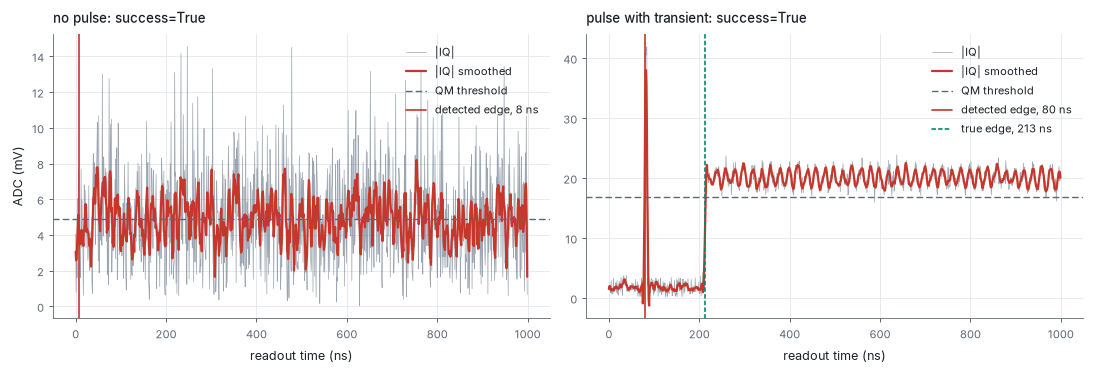

In [4]:
with style.theme_context(THEME):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
    for ax, name in zip(axes, ("no pulse", "pulse with transient")):
        ds, fit = synthetic[name], synthetic_fits[name]
        ax.plot(t, ds.IQ_abs.values[0] * MV, color=P.data, lw=0.5, alpha=0.6, label="|IQ|")
        ax.plot(t, fit["filtered"] * MV, color=P.fail, lw=1.6, label="|IQ| smoothed")
        ax.axhline(fit["threshold"] * MV, color=P.muted, lw=1.0, ls=(0, (4, 3)), label="QM threshold")
        ax.axvline(fit["delay"], color=P.fail, lw=1.2, label=f"detected edge, {fit['delay']:.0f} ns")
        if name != "no pulse":
            ax.axvline(TRUE_EDGE, color=P.truth, lw=1.2, ls=(0, (2, 2)), label=f"true edge, {TRUE_EDGE} ns")
        ax.set_title(f"{name}: success={fit['success']}")
        ax.set_xlabel("readout time (ns)")
        ax.legend(loc="upper right", fontsize=8)
    axes[0].set_ylabel("ADC (mV)")
    fig.tight_layout()
    plt.show()

With no pulse, the smoothed noise crosses its own mean within the first few samples, so QM's code
returns a delay of a few ns with `success=True`. With the transient, the first crossing is the
transient, and again `success=True`. The clean pulse without the transient is found at the right
place (within 4 ns), so the detector does its job when the only thing above the threshold is the
pulse. The edge lands a few samples late because the threshold sits high on a smoothed step.

## 3. Why the threshold is not halfway between baseline and pulse

QM's threshold is the average of two means: from sample 100 to the end, and from the start to 100
samples before the end. On a 1000-sample window those two ranges overlap on 800 samples, so the
threshold is close to the mean of the whole trace. For a step from a baseline `b` to a level `a`
that fills a fraction `p` of the window, the whole-trace mean is `b + p (a - b)`. The threshold
therefore lands a fraction of about `p` of the way up the step, not at one half.

 pulse fraction  QM threshold  whole-trace mean  halfway
      0.05         0.028          0.050         0.5
      0.20         0.167          0.200         0.5
      0.35         0.333          0.350         0.5
      0.50         0.500          0.500         0.5
      0.65         0.667          0.650         0.5
      0.80         0.833          0.800         0.5
      0.95         0.972          0.950         0.5
largest |threshold - whole-trace mean| over the sweep: 0.044 of the step


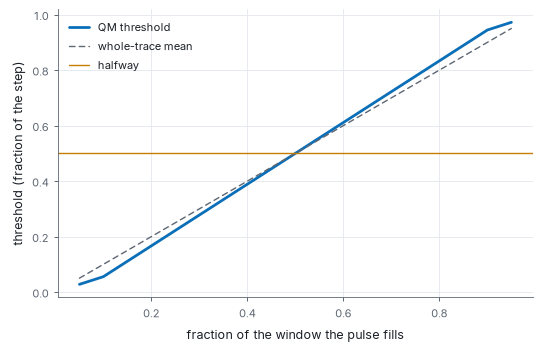

In [5]:
fractions = np.linspace(0.05, 0.95, 19)
rows = []
for p in fractions:
    step = (t >= round((1 - p) * N)).astype(float)  # baseline 0, pulse level 1
    thr = (step[100:].mean() + step[:-100].mean()) / 2
    rows.append((p, thr, step.mean()))
rows = np.array(rows)
print(" pulse fraction  QM threshold  whole-trace mean  halfway")
for p, thr, m in rows[::3]:
    print(f"      {p:4.2f}         {thr:5.3f}          {m:5.3f}         0.5")
print(f"largest |threshold - whole-trace mean| over the sweep: {np.max(np.abs(rows[:, 1] - rows[:, 2])):.3f} of the step")

with style.theme_context(THEME):
    fig, ax = plt.subplots(figsize=(5.5, 3.6))
    ax.plot(rows[:, 0], rows[:, 1], color=P.fit, lw=2, label="QM threshold")
    ax.plot(rows[:, 0], rows[:, 2], color=P.muted, lw=1, ls=(0, (4, 3)), label="whole-trace mean")
    ax.axhline(0.5, color=P.guess, lw=1, label="halfway")
    ax.set_xlabel("fraction of the window the pulse fills")
    ax.set_ylabel("threshold (fraction of the step)")
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

The same comparison on one simulated 0.1 V trace (simulator-dependent). The edge sits 213 samples
into the window, so the pulse fills most of it; the resonator also rings up after the edge, so the
level after the edge is not flat and "the pulse level" is taken as the mean after the edge.

In [6]:
state0 = load_state(INITIAL_STATE_PATH)
ctx = NodeContext(state=copy.deepcopy(state0), qpu=SimulatedQPU(seed=2026), save_outputs=False)
sim_ds = tof_analysis.process_raw_dataset(node.run_simulated(ctx, node.Parameters(readout_amplitude_in_v=0.1)))
sim_fit = assert_mirror_matches_qm(sim_ds)
f = sim_fit["filtered"]
edge_true = int(round(TRUE_DEVICE.time_of_flight - STORED_TOF))  # 213 samples into the window
base, after = f[:edge_true].mean(), f[edge_true:].mean()
print(f"window length {len(f)} samples, true edge at sample {edge_true}")
print(f"baseline mean {base * MV:.2f} mV, mean after the edge {after * MV:.2f} mV, halfway {(base + after) / 2 * MV:.2f} mV")
print(f"QM threshold {sim_fit['threshold'] * MV:.2f} mV, whole-trace mean {f.mean() * MV:.2f} mV")
print(f"QM threshold is {(sim_fit['threshold'] - base) / (after - base):.2f} of the way from baseline to the mean after the edge")

window length 1000 samples, true edge at sample 213
baseline mean 4.99 mV, mean after the edge 17.09 mV, halfway 11.04 mV
QM threshold 14.84 mV, whole-trace mean 14.51 mV
QM threshold is 0.81 of the way from baseline to the mean after the edge


The consequence for section 2: with no pulse there is no step, the threshold is just the mean of the
noise, and about half of all samples are above it. Some sample always crosses, usually one of the
first few.

## 4. Simulator-dependent: edge placement against amplitude and noise

**Everything in this section depends on this repo's simulator**, in particular on its assumed ADC
noise, `Device.adc_sample_noise` = 38 mV rms per 1 ns sample and input (`simulator/device.py`), and
its readout gain of 0.2 V at the ADC per volt of readout amplitude. Neither number was measured on
QM hardware. The noise sets the per-sample signal-to-noise ratio, and that sets whether a noise
excursion before the edge reaches the threshold.

Each run is the node as this repo runs it: window opening at the stored 24 ns, 100 averages, QM's
analysis, the state update. A run counts as off when the stored time of flight is more than 4 ns
from the true 237 ns. Readout amplitude 0.01 to 0.12 V, 30 seeds each, at 0.5x, 1x and 2x the assumed noise.

In [7]:
AMPLITUDES = np.round(np.arange(0.01, 0.1201, 0.01), 3)
NOISE_SCALES = (0.5, 1.0, 2.0)
SEEDS = range(30)
TRUE_TOF = TRUE_DEVICE.time_of_flight

t0 = time.perf_counter()
runs = []
for scale in NOISE_SCALES:
    device = dataclasses.replace(TRUE_DEVICE, adc_sample_noise=TRUE_DEVICE.adc_sample_noise * scale)
    for amp in AMPLITUDES:
        for seed in SEEDS:
            ctx = NodeContext(state=copy.deepcopy(state0), qpu=SimulatedQPU(device=device, seed=seed), save_outputs=False)
            fit = node.run(ctx, node.Parameters(readout_amplitude_in_v=float(amp)))
            stored = ctx.qubit["resonator"]["time_of_flight"]
            runs.append({
                "scale": scale, "amp": float(amp), "seed": seed, "success": fit["success"], "stored": stored,
                "off": abs(stored - TRUE_TOF) > 4, "fit": fit,
            })
print(f"{len(runs)} runs in {time.perf_counter() - t0:.1f} s")
print(f"runs reporting success: {sum(r['success'] for r in runs)} of {len(runs)}")

rate = {(s, a): np.mean([r["off"] for r in runs if r["scale"] == s and r["amp"] == a]) for s in NOISE_SCALES for a in AMPLITUDES}
print("\nfraction of runs off (stored time of flight more than 4 ns from 237 ns), 30 seeds each")
print("amplitude (V)  " + "  ".join(f"{s:>4.1f}x noise" for s in NOISE_SCALES))
for a in AMPLITUDES:
    print(f"    {a:5.2f}      " + "  ".join(f"{rate[(s, a)]:>10.0%}" for s in NOISE_SCALES))

1080 runs in 3.1 s
runs reporting success: 1080 of 1080

fraction of runs off (stored time of flight more than 4 ns from 237 ns), 30 seeds each
amplitude (V)   0.5x noise   1.0x noise   2.0x noise
     0.01            100%        100%        100%
     0.02             97%        100%        100%
     0.03             10%        100%        100%
     0.04              0%         90%        100%
     0.05              0%         37%        100%
     0.06              0%          3%        100%
     0.07              0%          0%         97%
     0.08              0%          0%         90%
     0.09              0%          0%         57%
     0.10              0%          0%         27%
     0.11              0%          0%          7%
     0.12              0%          0%          7%


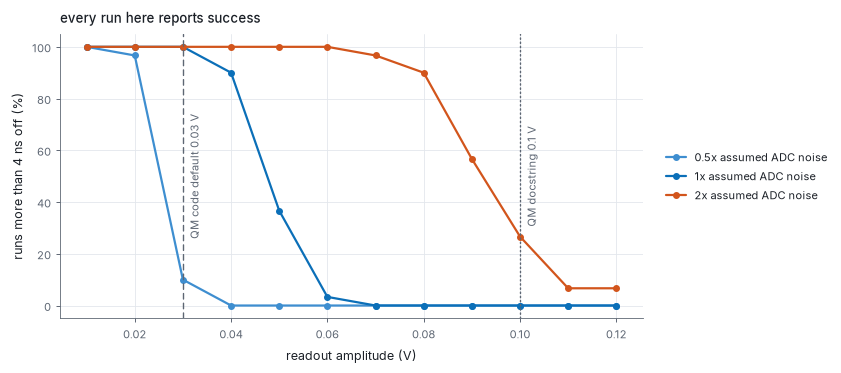

In [8]:
with style.theme_context(THEME):
    fig, ax = plt.subplots(figsize=(8.5, 3.8))
    colors = {0.5: P.ground, 1.0: P.fit, 2.0: P.excited}
    for s in NOISE_SCALES:
        ax.plot(AMPLITUDES, [rate[(s, a)] * 100 for a in AMPLITUDES], "o-", color=colors[s], lw=1.6, ms=4,
                label=f"{s:g}x assumed ADC noise")
    ax.axvline(0.03, color=P.muted, lw=1, ls=(0, (4, 3)))
    ax.axvline(0.1, color=P.muted, lw=1, ls=(0, (1, 2)))
    ax.text(0.031, 50, "QM code default 0.03 V", fontsize=8, color=P.muted, rotation=90, va="center")
    ax.text(0.101, 50, "QM docstring 0.1 V", fontsize=8, color=P.muted, rotation=90, va="center")
    ax.set_xlabel("readout amplitude (V)")
    ax.set_ylabel("runs more than 4 ns off (%)")
    ax.set_title("every run here reports success")
    ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.02, 0.5))
    fig.tight_layout()
    plt.show()

At the assumed noise, 0.03 V places the edge more than 4 ns off in every run, while 0.1 V places it
within 4 ns in every run. At half the noise 0.03 V is within 4 ns in most runs; at twice the noise
0.1 V is off in some. How 0.03 V does on a real setup depends on that setup's ADC signal-to-noise
ratio, which
this simulator only assumes. The part that does not depend on the simulator is that every one of
these off runs reported success, for the reason shown in section 2.

## 5. A proposed check (a suggestion, not QM's code)

Require a real step at the detected edge: the median of the smoothed trace over the 50 samples
after the edge, minus the median over the 50 samples before it, must exceed `k` times the standard
deviation of the smoothed trace over those 50 baseline samples. An edge with fewer than 50 samples
before it (or after it) is rejected, because there is no baseline to compare against; such an edge
cannot be told apart from noise at the window start or from a window that opened after the pulse
arrived.

Medians instead of means make the check ignore a short transient like the one in section 2: a
5-sample bump inside a 50-sample window moves the mean but not the median.

`k = 4` was chosen after looking at the section 4 runs below, so the false-reject and pass-through rates
are in-sample numbers for this simulator, not a validated operating point.

In [9]:
EDGE_WINDOW = 50
K = 4.0


def edge_step_check(fit: dict, window: int = EDGE_WINDOW, k: float = K) -> tuple[bool, float]:
    """(passes, step / baseline std) for the edge QM's detector picked; NaN when there is no room."""
    f = np.asarray(fit["filtered"])
    i = int(np.argmax(f > fit["threshold"]))  # the sample QM's detector picked, before 4 ns rounding
    if i < window or i + window > len(f):
        return False, float("nan")
    step = np.median(f[i:i + window]) - np.median(f[i - window:i])
    z = float(step / np.std(f[i - window:i]))
    return z > k, z


for name, fit in synthetic_fits.items():
    ok, z = edge_step_check(fit)
    print(f"{name:22s} QM success={fit['success']!s:5s}  proposed check passes={ok!s:5s}  step/std={z:.1f}")

no pulse               QM success=True   proposed check passes=False  step/std=nan
clean pulse            QM success=True   proposed check passes=True   step/std=6.7
pulse with transient   QM success=True   proposed check passes=False  step/std=0.0


In [10]:
good = [r for r in runs if not r["off"]]
bad = [r for r in runs if r["off"]]
for r in runs:
    r["check"], r["z"] = edge_step_check(r["fit"])
false_reject = np.mean([not r["check"] for r in good])
missed = np.mean([r["check"] for r in bad])
print(f"good runs (within 4 ns): {len(good)}, false-rejected by the check: {sum(not r['check'] for r in good)} ({false_reject:.1%})")
print(f"runs more than 4 ns off: {len(bad)}, passed by the check: {sum(r['check'] for r in bad)} ({missed:.1%}); "
      f"{sum(np.isnan(r['z']) for r in bad)} of them rejected for having no 50-sample baseline")
print("\nfalse-reject rate on good runs by noise level")
for s in NOISE_SCALES:
    g = [r for r in good if r["scale"] == s]
    print(f"  {s:3.1f}x noise: {sum(not r['check'] for r in g)} of {len(g)}")
g01 = [r for r in good if r["scale"] == 1.0 and r["amp"] == 0.1]
print(f"at 0.1 V and 1x noise: {sum(not r['check'] for r in g01)} of {len(g01)} good runs rejected")
z_good = np.array([r["z"] for r in good])
z_bad = np.array([r["z"] for r in bad if np.isfinite(r["z"])])
print(f"step/std: good runs min {z_good.min():.2f}, median {np.median(z_good):.2f}; off runs with a baseline max {z_bad.max():.2f}")
CHECK_FALSE_REJECT = false_reject
CHECK_MISSED = missed

good runs (within 4 ns): 624, false-rejected by the check: 32 (5.1%)
runs more than 4 ns off: 456, passed by the check: 0 (0.0%); 343 of them rejected for having no 50-sample baseline

false-reject rate on good runs by noise level
  0.5x noise: 5 of 298
  1.0x noise: 9 of 231
  2.0x noise: 18 of 95
at 0.1 V and 1x noise: 0 of 30 good runs rejected
step/std: good runs min 2.43, median 7.05; off runs with a baseline max 3.78


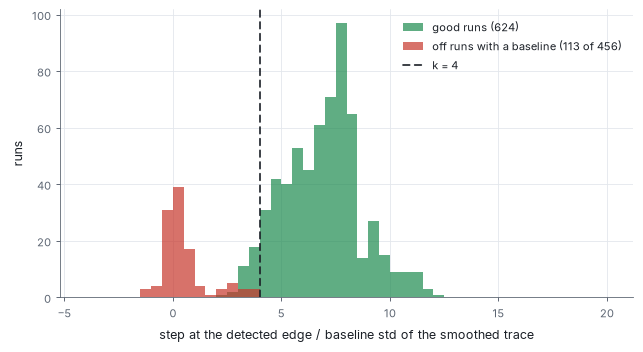

In [11]:
with style.theme_context(THEME):
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    bins = np.linspace(-4, 20, 49)
    ax.hist(np.clip(z_good, bins[0], bins[-1]), bins=bins, color=P.ok, alpha=0.7, label=f"good runs ({len(z_good)})")
    ax.hist(np.clip(z_bad, bins[0], bins[-1]), bins=bins, color=P.fail, alpha=0.7,
            label=f"off runs with a baseline ({len(z_bad)} of {len(bad)})")
    ax.axvline(K, color=P.fg, lw=1.2, ls=(0, (4, 3)), label=f"k = {K:g}")
    ax.set_xlabel("step at the detected edge / baseline std of the smoothed trace")
    ax.set_ylabel("runs")
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

The check rejects every off run in section 4 and both section 2 traces that have no edge at the detected sample, at the cost of
rejecting some good runs, mostly at twice the assumed noise where the step is small. The margin is
narrow: the largest step among off runs is close to `k`. A rejected run is a prompt to raise the
amplitude or the number of averages and rerun, which is cheap, so erring toward rejection seems the
better trade, but that is a judgement, not a measurement.

In [12]:
print(f"notebook runtime {time.perf_counter() - T_START:.1f} s")

notebook runtime 3.6 s
